In [1]:
import numpy as np
import pandas as pd
import random
import statsmodels
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.layers import Embedding
from sklearn.model_selection import train_test_split

In [2]:
df_fin_1 = pd.read_excel(r"D:\FY25-26\Quant Fund\data\formatted_ts_data_25_05_2025.xlsx")

#### Missing value Analysis

(array([14.,  4.,  0.,  0.,  0.,  0.,  0.,  0.,  9.,  6.]),
 array([ 0.        ,  9.8298493 , 19.65969859, 29.48954789, 39.31939718,
        49.14924648, 58.97909577, 68.80894507, 78.63879436, 88.46864366,
        98.29849295]),
 <BarContainer object of 10 artists>)

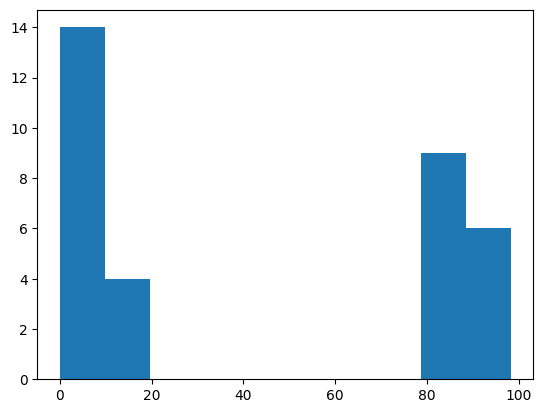

In [3]:
df_missing = pd.DataFrame(df_fin_1.isna().sum()).reset_index(drop=False).rename(columns={'index':'col',0:'missing'})
df_missing['missing_perc'] = df_missing['missing'].divide(df_fin_1.shape[0])*100
plt.hist(df_missing['missing_perc'])

In [4]:
df_missing[df_missing['missing_perc']>80].shape

(15, 3)

In [86]:
df_missing[df_missing['missing_perc']>80]['col'].to_list()

['Revenue_QoQ_growth',
 'Revenue_YoY_growth',
 'EBITDA_QoQ_growth',
 'EBITDA_YoY_growth',
 'NI_QoQ_growth',
 'NI_YoY_growth',
 'Abn_Gain_Loss_QoQ_growth',
 'Abn_Gain_Loss_YoY_growth',
 'CFO_QoQ_growth',
 'CFO_YoY_growth',
 'ROE',
 'ROA',
 'ROCE',
 'D/E',
 'Ast_TO']

In [5]:
missing_cols_drop = df_missing[df_missing['missing_perc']>80]['col'].to_list()
df_fin_1.drop(columns=missing_cols_drop,inplace=True)
df_fin_1.reset_index(drop=True,inplace=True)

In [103]:
iv_cols = list(df_fin_1.columns)
misc_cols = ['Ticker','Quarter','Mkt_Cap','Target','Returns','Rank']
for col in misc_cols:
    iv_cols.remove(col)

### Data Split Train-Test

In [7]:
all_qtrs = list(df_fin_1['Quarter'].unique())

In [8]:
no_of_diff_splits = 5
test_size = 0.2
list_of_dates_split_df = []
for i in range(no_of_diff_splits):
    train_dates, test_dates = train_test_split(all_qtrs, test_size=test_size, shuffle=True)
    df_test_dates1 = pd.DataFrame({'Quarter':test_dates,'Set':['Test']*len(test_dates)})
    df_train_dates1 = pd.DataFrame({'Quarter':train_dates,'Set':['Train']*len(train_dates)})
    df_dates_split = pd.concat([df_test_dates1,df_train_dates1],axis=0)
    list_of_dates_split_df.append(df_dates_split)

In [9]:
# with pd.ExcelWriter(rf'D:\FY25-26\Quant Fund\data\data_splits_25_05_2025_test_size_{test_size*100}%.xlsx', engine='xlsxwriter') as writer:
#     for i,df_dates_split1 in enumerate(list_of_dates_split_df):
#         df_dates_split1.to_excel(writer,sheet_name=f'Split{i+0}',index=False)

In [104]:
#### Considering 1st Random split
print(test_size)
df_splits = pd.read_excel(rf'D:\FY25-26\Quant Fund\data\data_splits_25_05_2025_test_size_{test_size*100}%.xlsx',sheet_name='Split1')

0.2


In [105]:
df_fin_11 = df_fin_1.merge(df_splits,on='Quarter',how='left')

In [106]:
df_fin_11['Set'].isna().sum()

np.int64(0)

In [107]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [108]:
df_fin_11['Quarter'] = df_fin_11['Quarter'].apply(convert_qtr_to_date)

In [109]:
df_fin_11.sort_values(by=['Ticker','Quarter'],inplace=True)

#### Split Data into Train-Test

In [110]:
df_train = df_fin_11[df_fin_11['Set']=='Train']
df_test = df_fin_11[df_fin_11['Set']=='Test']

#### imputation

In [111]:
df_train.columns

Index(['Price_QoQ_growth', 'Price_YoY_growth', '200D_MVA_QoQ_growth',
       '200D_MVA_YoY_growth', '50D_MVA_QoQ_growth', '50D_MVA_YoY_growth',
       'Dividend_QoQ_growth', 'Dividend_YoY_growth', 'Volume_QoQ_growth',
       'Volume_YoY_growth', 'P/E', 'P/B', 'Mkt_Cap', 'Returns', 'Ticker',
       'Quarter', 'Target', 'Rank', 'Set'],
      dtype='object')

In [112]:
iv_cols

['Price_QoQ_growth',
 'Price_YoY_growth',
 '200D_MVA_QoQ_growth',
 '200D_MVA_YoY_growth',
 '50D_MVA_QoQ_growth',
 '50D_MVA_YoY_growth',
 'Dividend_QoQ_growth',
 'Dividend_YoY_growth',
 'Volume_QoQ_growth',
 'Volume_YoY_growth',
 'P/E',
 'P/B']

In [113]:
df_train.loc[:,'Quarter'] = pd.to_datetime(df_train['Quarter'],dayfirst=True)
df_test.loc[:,'Quarter'] = pd.to_datetime(df_test['Quarter'],dayfirst=True)

In [114]:
df_train = df_train.set_index(['Quarter'])
df_test = df_test.set_index(['Quarter'])

d:\Quant Fund\qf_32\lib\site-packages\pandas\core\indexes\base.py:7588: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


In [ ]:
for col in iv_cols:
    df_train.loc[:,col] = df_train[col].astype(float)
    df_test.loc[:,col] = df_test[col].astype(float)
    df_train.loc[:,col] = df_train.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))
    df_test.loc[:,col] = df_test.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))

In [117]:
df_train.isna().sum()

Price_QoQ_growth        25
Price_YoY_growth       127
200D_MVA_QoQ_growth    131
200D_MVA_YoY_growth    226
50D_MVA_QoQ_growth      51
50D_MVA_YoY_growth     147
Dividend_QoQ_growth    593
Dividend_YoY_growth    792
Volume_QoQ_growth       30
Volume_YoY_growth      137
P/E                    565
P/B                    434
Mkt_Cap                  0
Returns                  0
Ticker                   0
Target                   0
Rank                     0
Set                      0
dtype: int64

In [118]:
df_train.reset_index(inplace=True)
df_test.reset_index(inplace=True)

In [119]:
for col in iv_cols:
    df_train.loc[:,col] = df_train.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))
    df_test.loc[:,col] = df_test.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))

In [120]:
# med_values = {}
# for col in iv_cols:
#     med_values[col] = df_train[col].median()
df_test.isna().sum()


Quarter                0
Price_QoQ_growth       0
Price_YoY_growth       0
200D_MVA_QoQ_growth    0
200D_MVA_YoY_growth    0
50D_MVA_QoQ_growth     0
50D_MVA_YoY_growth     0
Dividend_QoQ_growth    0
Dividend_YoY_growth    0
Volume_QoQ_growth      0
Volume_YoY_growth      0
P/E                    0
P/B                    0
Mkt_Cap                0
Returns                0
Ticker                 0
Target                 0
Rank                   0
Set                    0
dtype: int64

In [121]:
df_train['Ticker'].nunique()

439

In [122]:
df_train['Year'] = df_train['Quarter'].dt.year
df_train['Quarter_number'] = df_train['Quarter'].dt.quarter

#### Multi-collinearity check

In [123]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [124]:
iv_cols

['Price_QoQ_growth',
 'Price_YoY_growth',
 '200D_MVA_QoQ_growth',
 '200D_MVA_YoY_growth',
 '50D_MVA_QoQ_growth',
 '50D_MVA_YoY_growth',
 'Dividend_QoQ_growth',
 'Dividend_YoY_growth',
 'Volume_QoQ_growth',
 'Volume_YoY_growth',
 'P/E',
 'P/B']

In [125]:
iv_cols = iv_cols + ['Year','Quarter_number']

In [126]:
vif_data = pd.DataFrame()
vif_data["feature"] = iv_cols

In [127]:
df_train[iv_cols].isin([np.inf,-np.inf]).sum()

Price_QoQ_growth       0
Price_YoY_growth       0
200D_MVA_QoQ_growth    0
200D_MVA_YoY_growth    0
50D_MVA_QoQ_growth     0
50D_MVA_YoY_growth     0
Dividend_QoQ_growth    0
Dividend_YoY_growth    0
Volume_QoQ_growth      0
Volume_YoY_growth      0
P/E                    0
P/B                    0
Year                   0
Quarter_number         0
dtype: int64

In [128]:
for col in iv_cols:
    df_train.loc[:,col] = df_train[col].astype(float)

In [129]:
vif_data["VIF"] = [variance_inflation_factor(df_train[iv_cols].values, i) for i in range(len(iv_cols))]

In [130]:
vif_data.head()

,feature,VIF
0,Price_QoQ_growth,4.025210
1,Price_YoY_growth,9.895893
2,200D_MVA_QoQ_growth,2.389572
3,200D_MVA_YoY_growth,5.238407
4,50D_MVA_QoQ_growth,4.189840


In [138]:
vif_cols = vif_data[vif_data['VIF']<5]['feature'].to_list()
vif_cols

['Price_QoQ_growth',
 '200D_MVA_QoQ_growth',
 '50D_MVA_QoQ_growth',
 'Dividend_QoQ_growth',
 'Dividend_YoY_growth',
 'Volume_QoQ_growth',
 'Volume_YoY_growth',
 'P/E',
 'P/B']

In [139]:
import seaborn as sns

In [140]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train[vif_cols+['Target']].corr().style.background_gradient(cmap='coolwarm')

,Price_QoQ_growth,200D_MVA_QoQ_growth,50D_MVA_QoQ_growth,Dividend_QoQ_growth,Dividend_YoY_growth,Volume_QoQ_growth,Volume_YoY_growth,P/E,P/B,Target
Price_QoQ_growth,1.000000,0.264698,0.838190,-0.194747,-0.100057,0.037499,0.018402,0.013868,0.033649,0.025987
200D_MVA_QoQ_growth,0.264698,1.000000,0.393387,-0.047624,-0.286272,-0.016912,0.008125,0.025939,0.087612,0.050148
50D_MVA_QoQ_growth,0.838190,0.393387,1.000000,-0.143753,-0.129563,0.017111,0.002504,0.016018,0.037041,0.035716
Dividend_QoQ_growth,-0.194747,-0.047624,-0.143753,1.000000,0.262584,-0.003087,-0.011125,-0.011880,-0.007690,0.000971
Dividend_YoY_growth,-0.100057,-0.286272,-0.129563,0.262584,1.000000,0.009525,-0.008302,-0.023797,-0.020504,-0.009455
Volume_QoQ_growth,0.037499,-0.016912,0.017111,-0.003087,0.009525,1.000000,0.719779,0.001702,0.007189,0.007129
Volume_YoY_growth,0.018402,0.008125,0.002504,-0.011125,-0.008302,0.719779,1.000000,0.006206,0.007929,-0.003483
P/E,0.013868,0.025939,0.016018,-0.011880,-0.023797,0.001702,0.006206,1.000000,0.146741,0.002011
P/B,0.033649,0.087612,0.037041,-0.007690,-0.020504,0.007189,0.007929,0.146741,1.000000,-0.015729
Target,0.025987,0.050148,0.035716,0.000971,-0.009455,0.007129,-0.003483,0.002011,-0.015729,1.000000


In [141]:
for col in ['Volume_QoQ_growth','Price_QoQ_growth']:
    vif_cols.remove(col)

In [142]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train[vif_cols+['Target']].corr().style.background_gradient(cmap='coolwarm')

,200D_MVA_QoQ_growth,50D_MVA_QoQ_growth,Dividend_QoQ_growth,Dividend_YoY_growth,Volume_YoY_growth,P/E,P/B,Target
200D_MVA_QoQ_growth,1.000000,0.393387,-0.047624,-0.286272,0.008125,0.025939,0.087612,0.050148
50D_MVA_QoQ_growth,0.393387,1.000000,-0.143753,-0.129563,0.002504,0.016018,0.037041,0.035716
Dividend_QoQ_growth,-0.047624,-0.143753,1.000000,0.262584,-0.011125,-0.011880,-0.007690,0.000971
Dividend_YoY_growth,-0.286272,-0.129563,0.262584,1.000000,-0.008302,-0.023797,-0.020504,-0.009455
Volume_YoY_growth,0.008125,0.002504,-0.011125,-0.008302,1.000000,0.006206,0.007929,-0.003483
P/E,0.025939,0.016018,-0.011880,-0.023797,0.006206,1.000000,0.146741,0.002011
P/B,0.087612,0.037041,-0.007690,-0.020504,0.007929,0.146741,1.000000,-0.015729
Target,0.050148,0.035716,0.000971,-0.009455,-0.003483,0.002011,-0.015729,1.000000


In [1]:
df_train[['Ticker','Quarter']+vif_cols+['Target']].head()

NameError: name 'df_train' is not defined

In [145]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [146]:
df_train.columns

Index(['Quarter', 'Price_QoQ_growth', 'Price_YoY_growth',
       '200D_MVA_QoQ_growth', '200D_MVA_YoY_growth', '50D_MVA_QoQ_growth',
       '50D_MVA_YoY_growth', 'Dividend_QoQ_growth', 'Dividend_YoY_growth',
       'Volume_QoQ_growth', 'Volume_YoY_growth', 'P/E', 'P/B', 'Mkt_Cap',
       'Returns', 'Ticker', 'Target', 'Rank', 'Set', 'Year', 'Quarter_number'],
      dtype='object')

In [2]:
# iv_cols = list(df_train.columns)
# misc_cols = ['Ticker','Quarter','Target','Rank','Returns','Quarter_number','Year']
# for col in misc_cols:
#     iv_cols.remove(col)

In [150]:
# iv_cols

In [151]:
from sklearn.preprocessing import StandardScaler

In [152]:
scaler = StandardScaler()

In [153]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [154]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [156]:
for col in ['Ticker','Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [157]:
from sklearn.preprocessing import LabelEncoder

# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [158]:
df_train1['Ticker_encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_encoded'] = label_encoder.transform(df_test1['Ticker'])

In [159]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [160]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Quant Fund\qf_32\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [161]:

features = list(df_train1.columns)
features.remove('Target')
features.remove('Ticker')
features

['200D_MVA_QoQ_growth',
 '50D_MVA_QoQ_growth',
 'Dividend_QoQ_growth',
 'Dividend_YoY_growth',
 'Volume_YoY_growth',
 'P/E',
 'P/B',
 'Quarter',
 'Ticker_encoded']

In [163]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (11400, 1, 8)
y_train shape: (11400,)
X_test shape: (2999, 1, 8)
y_test shape: (2999,)


In [164]:
ticker_encoded_train = df_train1['Ticker_encoded'].values
ticker_encoded_test = df_test1['Ticker_encoded'].values

In [193]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score

def calculate_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    confusion = confusion_matrix(y_true,y_pred)
    
    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }


from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.75, patience=20, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    # Train the model
    
    # Make predictions for the datasets
    y_train_pred = (model.predict([ticker_encoded_train, X_train]) >= 0.5).astype(int)
    y_test_pred = (model.predict([ticker_encoded_test, X_test]) >= 0.5).astype(int)
    print(len(ticker_encoded_test),len(X_test))
    y_test_pred = (model.predict([ticker_encoded_test, X_test]) >= 0.5).astype(int)
    
    # Calculate metrics
    train_metrics = calculate_metrics(y_train, y_train_pred)
    test_metrics = calculate_metrics(y_test, y_test_pred)
    test_metrics = calculate_metrics(y_test, y_test_pred)
    
    # Combine metrics into a DataFrame
    metrics_df = pd.DataFrame({
        'set': ['train', 'test'],
        'accuracy': [train_metrics['accuracy'], test_metrics['accuracy']],
        'precision': [train_metrics['precision'], test_metrics['precision']],
        'recall': [train_metrics['recall'], test_metrics['recall']],
        'f1': [train_metrics['f1'], test_metrics['f1']],
        'confusion_matrix': [train_metrics['confusion_matrix'], test_metrics['confusion_matrix']]
    })
    
    return metrics_df


#### LSTM

In [178]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model

def build_lstm_model(input_shape, embedding_size, num_tickers):
    # Define input layers
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")  # e.g., (1, 13) for time_steps=1, 13 features
    ticker_input = Input(shape=(1,), name="ticker_input")  
    
    # Embedding layer for tickers
    ticker_embedding_layer = Embedding(input_dim=num_tickers, output_dim=embedding_size, input_length=1)(ticker_input)
    
    # Flatten ticker embedding
    ticker_embedding_flat = Flatten()(ticker_embedding_layer)
    
    # Reshape ticker embedding to match continuous_input shape for concatenation
    ticker_embedding_reshaped = Reshape((embedding_size,))(ticker_embedding_flat)  # Now (batch_size, embedding_size)

    # Expand ticker embedding to match the features of continuous input
    ticker_embedding_expanded = RepeatVector(input_shape[1])(ticker_embedding_reshaped)  # (batch_size, time_steps, embedding_size)

    # Concatenate the ticker embedding with the continuous input (time_steps = 1)
    merged = Concatenate(axis=2)([ticker_embedding_expanded, continuous_input])  # Concatenate along the feature axis (axis=2)

    # LSTM layer
    lstm_layer = LSTM(64, activation='relu')(merged)  # LSTM over concatenated data

    # Dense output layer
    output = Dense(1, activation='sigmoid')(lstm_layer)  # Binary classification output

    # Build the model
    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    
    return model


In [179]:
from tensorflow.keras.metrics import AUC, Precision

In [180]:
num_tickers = len(label_encoder.classes_)

In [181]:

# Define LSTM model
lstm_model = build_lstm_model(X_train.shape, embedding_size, num_tickers)
lstm_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

d:\Quant Fund\qf_32\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Epoch 23: ReduceLROnPlateau reducing learning rate to 0.0004218749818392098.
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
2999 2999
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


,set,accuracy,precision,recall,f1,confusion_matrix
0,train,0.852456,0.675000,0.031579,0.060335,"[[9664, 26], [1656, 54]]"
1,test,0.843948,0.090909,0.004444,0.008475,"[[2529, 20], [448, 2]]"


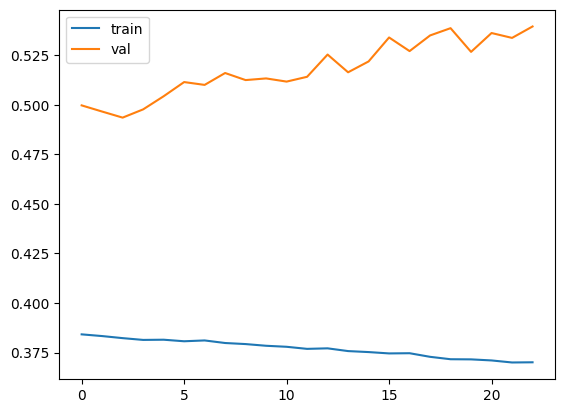

In [195]:
lstm_metrics_df = process_and_evaluate1(
    lstm_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_encoded']), np.array(df_test1['Ticker_encoded'])
    ,checkpoint_path=r'checkpoints1\lstm.keras',epochs=500,batch_size=32
)

# Print the metrics
lstm_metrics_df

#### Log transformations

In [196]:
def log_transformation(x: pd.Series) -> pd.Series:
    # Function np.log1p = log(x + 1)
    return np.log1p(x)

def log_inverse_transformation(x: pd.Series) -> pd.Series:
    # Function np.expm1(x) = exp(x) - 1
    return np.expm1(x)

In [ ]:
X_train_log = np.log(X_train)
X_test_log = np.log(X_test)

C:\Users\35098\AppData\Local\Temp\ipykernel_20980\3871042690.py:1: RuntimeWarning: divide by zero encountered in log
  X_train_log = np.log(X_train)
C:\Users\35098\AppData\Local\Temp\ipykernel_20980\3871042690.py:1: RuntimeWarning: invalid value encountered in log
  X_train_log = np.log(X_train)
C:\Users\35098\AppData\Local\Temp\ipykernel_20980\3871042690.py:2: RuntimeWarning: invalid value encountered in log
  X_test_log = np.log(X_test)



Epoch 20: ReduceLROnPlateau reducing learning rate to 0.00023730468819849193.
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
2999 2999
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


d:\Quant Fund\qf_32\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Quant Fund\qf_32\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Quant Fund\qf_32\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,set,accuracy,precision,recall,f1,confusion_matrix
0,train,0.85000,0.0,0.0,0.0,"[[9690, 0], [1710, 0]]"
1,test,0.84995,0.0,0.0,0.0,"[[2549, 0], [450, 0]]"


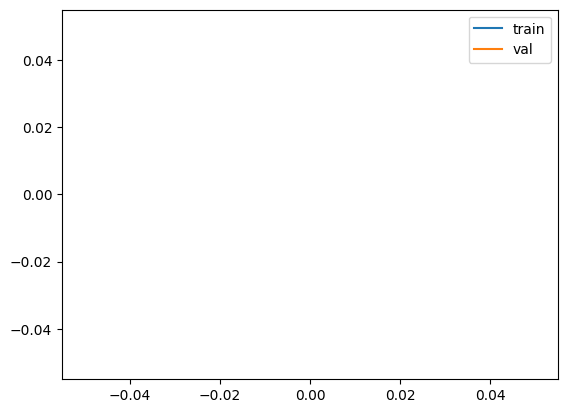

In [203]:
lstm_log_metrics_df = process_and_evaluate1(
    lstm_model,
    X_train_log, y_train,
    X_test_log, y_test,
    np.array(df_train1['Ticker_encoded']), np.array(df_test1['Ticker_encoded'])
    ,checkpoint_path=r'checkpoints1_log_transform\lstm.keras',epochs=500,batch_size=32
)

# Print the metrics
lstm_log_metrics_df

#### SQRT transformation

C:\Users\35098\AppData\Local\Temp\ipykernel_20980\4120169033.py:1: RuntimeWarning: invalid value encountered in sqrt
  X_train_sqrt = np.sqrt(X_train)
C:\Users\35098\AppData\Local\Temp\ipykernel_20980\4120169033.py:2: RuntimeWarning: invalid value encountered in sqrt
  X_test_sqrt = np.sqrt(X_test)



Epoch 20: ReduceLROnPlateau reducing learning rate to 0.00017797851614886895.
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
2999 2999
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


d:\Quant Fund\qf_32\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Quant Fund\qf_32\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Quant Fund\qf_32\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,set,accuracy,precision,recall,f1,confusion_matrix
0,train,0.85000,0.0,0.0,0.0,"[[9690, 0], [1710, 0]]"
1,test,0.84995,0.0,0.0,0.0,"[[2549, 0], [450, 0]]"


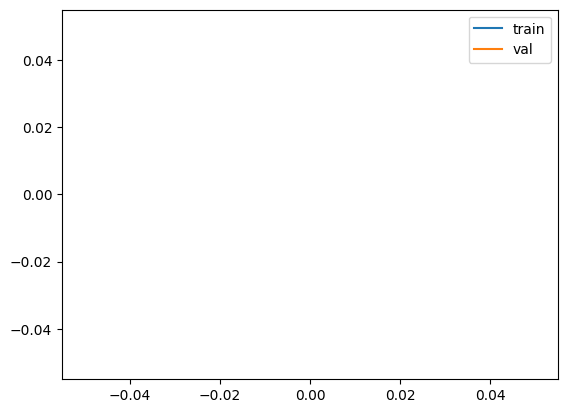

In [204]:
X_train_sqrt = np.sqrt(X_train)
X_test_sqrt = np.sqrt(X_test)
lstm_sqrt_metrics_df = process_and_evaluate1(
    lstm_model,
    X_train_sqrt, y_train,
    X_test_sqrt, y_test,
    np.array(df_train1['Ticker_encoded']), np.array(df_test1['Ticker_encoded'])
    ,checkpoint_path=r'checkpoints1_sqrt_transform\lstm.keras',epochs=500,batch_size=32
)

# Print the metrics
lstm_sqrt_metrics_df

#### Predictions analysis

In [207]:
df_train_pred = df_train[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred['Pred_Prob_lstm'] = pd.Series((lstm_model.predict([np.array(df_test1['Ticker_encoded']),X_test]).reshape(-1)))
df_train_pred['Pred_Prob_lstm'] = pd.Series((lstm_model.predict([np.array(df_train1['Ticker_encoded']),X_train]).reshape(-1)))

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
 26/357 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  

C:\Users\35098\AppData\Local\Temp\ipykernel_20980\3631833529.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred['Pred_Prob_lstm'] = pd.Series((lstm_model.predict([np.array(df_test1['Ticker_encoded']),X_test]).reshape(-1)))


357/357 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


C:\Users\35098\AppData\Local\Temp\ipykernel_20980\3631833529.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred['Pred_Prob_lstm'] = pd.Series((lstm_model.predict([np.array(df_train1['Ticker_encoded']),X_train]).reshape(-1)))


In [206]:
# df_test_pred.head()

#### Top30 as fund - irrespective of the prob values

In [ ]:

def label_prediction(row, model_name):
    in_top_30 = row[f'Top_30_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_30 and target == 1:
        return 'TP'
    elif in_top_30 and target == 0:
        return 'FP'
    elif not in_top_30 and target == 0:
        return 'TN'
    elif not in_top_30 and target == 1:
        return 'FN'


In [ ]:
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'

In [ ]:
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)

In [ ]:
df_pred.head()

,Ticker,Quarter_Date,Target,Returns,Rank,Pred_Prob_lstm,Set
0,RELIANCE IN,2007-06-30,0,35.133445,38.0,0.161504,Train
1,ONGC IN,2007-06-30,0,5.804400,122.0,0.151629,Train
2,BHARTI IN,2007-06-30,0,12.436952,101.0,0.218146,Train
3,NTPC IN,2007-06-30,0,26.937878,59.0,0.122074,Train
4,TCS IN,2007-06-30,0,-7.760841,173.0,0.202245,Train


In [ ]:
df_pred.shape

(14399, 7)

In [ ]:
df_train1.shape

(11399, 17)

In [ ]:
# df_pred.groupby(by=['Pred_Prob_lstm'])
df_pred['Top_30_Pred_Prob_lstm'] = df_pred.groupby('Quarter_Date')['Pred_Prob_lstm'].transform(lambda x: x.rank(ascending=False) <= 30)

In [ ]:
df_pred['Pred_Category'] = df_pred.apply(lambda row: label_prediction(row, model_name='lstm'), axis=1)

In [ ]:
df_pred.reset_index(drop=True,inplace=True)

In [ ]:
df_pred.head()

,Ticker,Quarter_Date,Target,Returns,Rank,Pred_Prob_lstm,Set,Top_30_Pred_Prob_lstm,Pred_Category
0,RELIANCE IN,2007-06-30,0,35.133445,38.0,0.161504,Train,False,TN
1,ONGC IN,2007-06-30,0,5.804400,122.0,0.151629,Train,False,TN
2,BHARTI IN,2007-06-30,0,12.436952,101.0,0.218146,Train,False,TN
3,NTPC IN,2007-06-30,0,26.937878,59.0,0.122074,Train,False,TN
4,TCS IN,2007-06-30,0,-7.760841,173.0,0.202245,Train,False,TN


In [ ]:
qtr_summary_df = df_pred.groupby('Quarter_Date').agg(
                    Set = ('Set','first'),
                    Avg_Returns=('Returns', 'mean'),
                    Count_TP=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

In [ ]:
qtr_summary_df.head()

,Quarter_Date,Set,Avg_Returns,Count_TP,Count_TN,Count_FP,Count_FN
0,2006-03-31,Train,-13.639512,9,149,21,21
1,2006-06-30,Test,17.196745,7,147,23,23
2,2006-09-30,Train,10.022142,9,149,21,21
3,2006-12-31,Train,-5.068156,12,152,18,18
4,2007-03-31,Train,19.900076,6,146,24,24


In [ ]:
set_summary_df = qtr_summary_df.groupby('Set').agg(
    Count_TP = ('Count_TP','sum'),
    Count_TN = ('Count_TN','sum'),
    Count_FP = ('Count_FP','sum'),
    Count_FN = ('Count_FN','sum')
)

In [ ]:

# with pd.ExcelWriter(r'D:\FY25-26\Quant Fund\data\Pred_Vs_Act_LSTM_26_05_2025.xlsx', engine='xlsxwriter') as writer:
#     df_pred.to_excel(writer, sheet_name='Pred_Vs_Act', index=False)
#     qtr_summary_df.to_excel(writer, sheet_name='Quarterly_Summary', index=False)
#     set_summary_df.to_excel(writer, sheet_name='Dataset_Summary', index=False)
